# **CREDIT CARD DEFAULT PREDICTION**
# Predict whether a customer will default on the next credit card payment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Credit Card Defaulter Prediction.csv")

In [3]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,F,University,Married,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,Y
1,2,120000,F,University,Single,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,Y
2,3,90000,F,University,Single,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,N
3,4,50000,F,University,Married,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,N
4,5,50000,M,University,Married,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,N


In [4]:
print(df.shape)
print()
print(df.columns)

(30000, 25)

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default '],
      dtype='object')


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         30000 non-null  int64 
 1   LIMIT_BAL  30000 non-null  int64 
 2   SEX        30000 non-null  object
 3   EDUCATION  30000 non-null  object
 4   MARRIAGE   30000 non-null  object
 5   AGE        30000 non-null  int64 
 6   PAY_0      30000 non-null  int64 
 7   PAY_2      30000 non-null  int64 
 8   PAY_3      30000 non-null  int64 
 9   PAY_4      30000 non-null  int64 
 10  PAY_5      30000 non-null  int64 
 11  PAY_6      30000 non-null  int64 
 12  BILL_AMT1  30000 non-null  int64 
 13  BILL_AMT2  30000 non-null  int64 
 14  BILL_AMT3  30000 non-null  int64 
 15  BILL_AMT4  30000 non-null  int64 
 16  BILL_AMT5  30000 non-null  int64 
 17  BILL_AMT6  30000 non-null  int64 
 18  PAY_AMT1   30000 non-null  int64 
 19  PAY_AMT2   30000 non-null  int64 
 20  PAY_AMT3   30000 non-null  i

In [6]:
df.describe()

,ID,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,...,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567
std,8660.398374,129747.661567,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,...,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775
min,1.000000,10000.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,...,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,...,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000
50%,15000.500000,140000.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,...,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000
75%,22500.250000,240000.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,...,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000
max,30000.000000,1000000.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,...,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000


**Observations**
1. Numerical columns are *Limit_id, Age, Bill_amts, Pay_amts*.
2. Categorical columns are *Sex, Education, Marriage, Pay(i.e ot repersented code format as cate)*.
3. Identifier is *ID*
4. Target is *Default(Categorical)*

In [7]:
print(df.isnull().sum())
#df[df.isnull().any(axis=1)]

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
default      0
dtype: int64


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.nunique()

ID           30000
LIMIT_BAL       81
SEX              2
EDUCATION        6
MARRIAGE         4
AGE             56
PAY_0           11
PAY_2           11
PAY_3           11
PAY_4           11
PAY_5           10
PAY_6           10
BILL_AMT1    22723
BILL_AMT2    22346
BILL_AMT3    22026
BILL_AMT4    21548
BILL_AMT5    21010
BILL_AMT6    20604
PAY_AMT1      7943
PAY_AMT2      7899
PAY_AMT3      7518
PAY_AMT4      6937
PAY_AMT5      6897
PAY_AMT6      6939
default          2
dtype: int64

In [10]:
df = df.rename(columns={"default ": "default","PAY_0":'PAY_1'})

In [11]:
df['default'] = df['default'].map({'N': 0, 'Y': 1})

In [12]:
df['default'].head()

0    1
1    1
2    0
3    0
4    0
Name: default, dtype: int64

In [13]:
print(df['default'].unique())
print(df['default'].value_counts())

[1 0]
default
0    23364
1     6636
Name: count, dtype: int64


In [14]:
print(df["SEX"].unique())
df["MARRIAGE"].unique()

['F' 'M']


array(['Married', 'Single', 'Other', '0'], dtype=object)

In [15]:
df["default"].value_counts(normalize=True)*100

default
0    77.88
1    22.12
Name: proportion, dtype: float64

Class Imbalance

77.88% customers did not default while 22.12% defaulted where target is imbalanced with N (i.e not default) as the majority class

Target Distribution

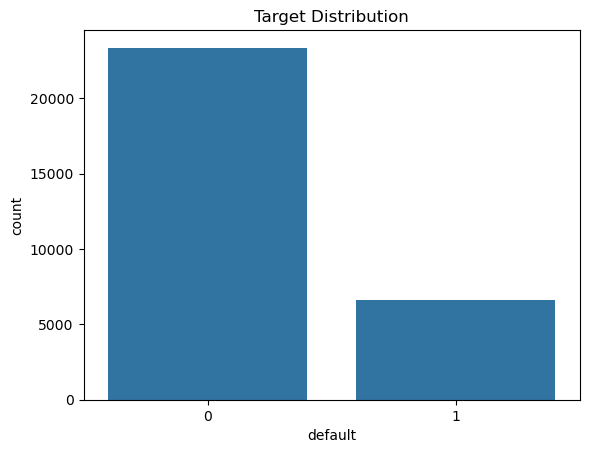

In [16]:
sns.countplot(x="default",data=df)
plt.title("Target Distribution")
plt.show()

The target distribution shows approximately 77.9% non-default customers and 22.1% default customers, indicating a moderately imbalanced target variable so that i wouldn't rely on accuracy alone and would evaluate the model using metrics such as precision, recall, F1-score, and ROC-AUC.. and you can observe visually i clear the class how distributed

**Numerical Analysis**

In [17]:
df.dtypes

ID            int64
LIMIT_BAL     int64
SEX          object
EDUCATION    object
MARRIAGE     object
AGE           int64
PAY_1         int64
PAY_2         int64
PAY_3         int64
PAY_4         int64
PAY_5         int64
PAY_6         int64
BILL_AMT1     int64
BILL_AMT2     int64
BILL_AMT3     int64
BILL_AMT4     int64
BILL_AMT5     int64
BILL_AMT6     int64
PAY_AMT1      int64
PAY_AMT2      int64
PAY_AMT3      int64
PAY_AMT4      int64
PAY_AMT5      int64
PAY_AMT6      int64
default       int64
dtype: object

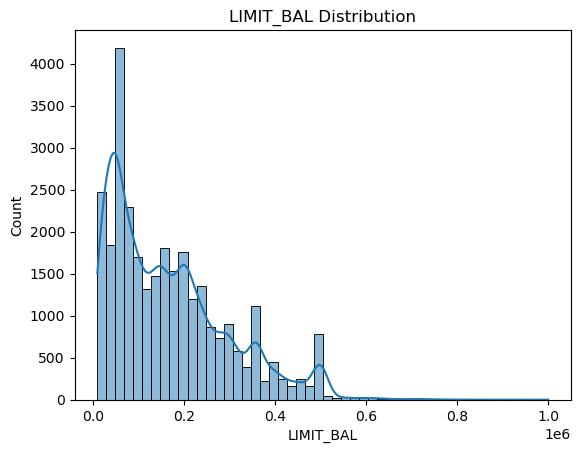

In [18]:
sns.histplot(df["LIMIT_BAL"],kde="TRUE",bins=50)
plt.title("LIMIT_BAL Distribution")
plt.show()

Clearly it shows rightlu skew.. Highest concentration of cust are blw 40k-50k and also customers have very high limits too

**Categorical Analysis**

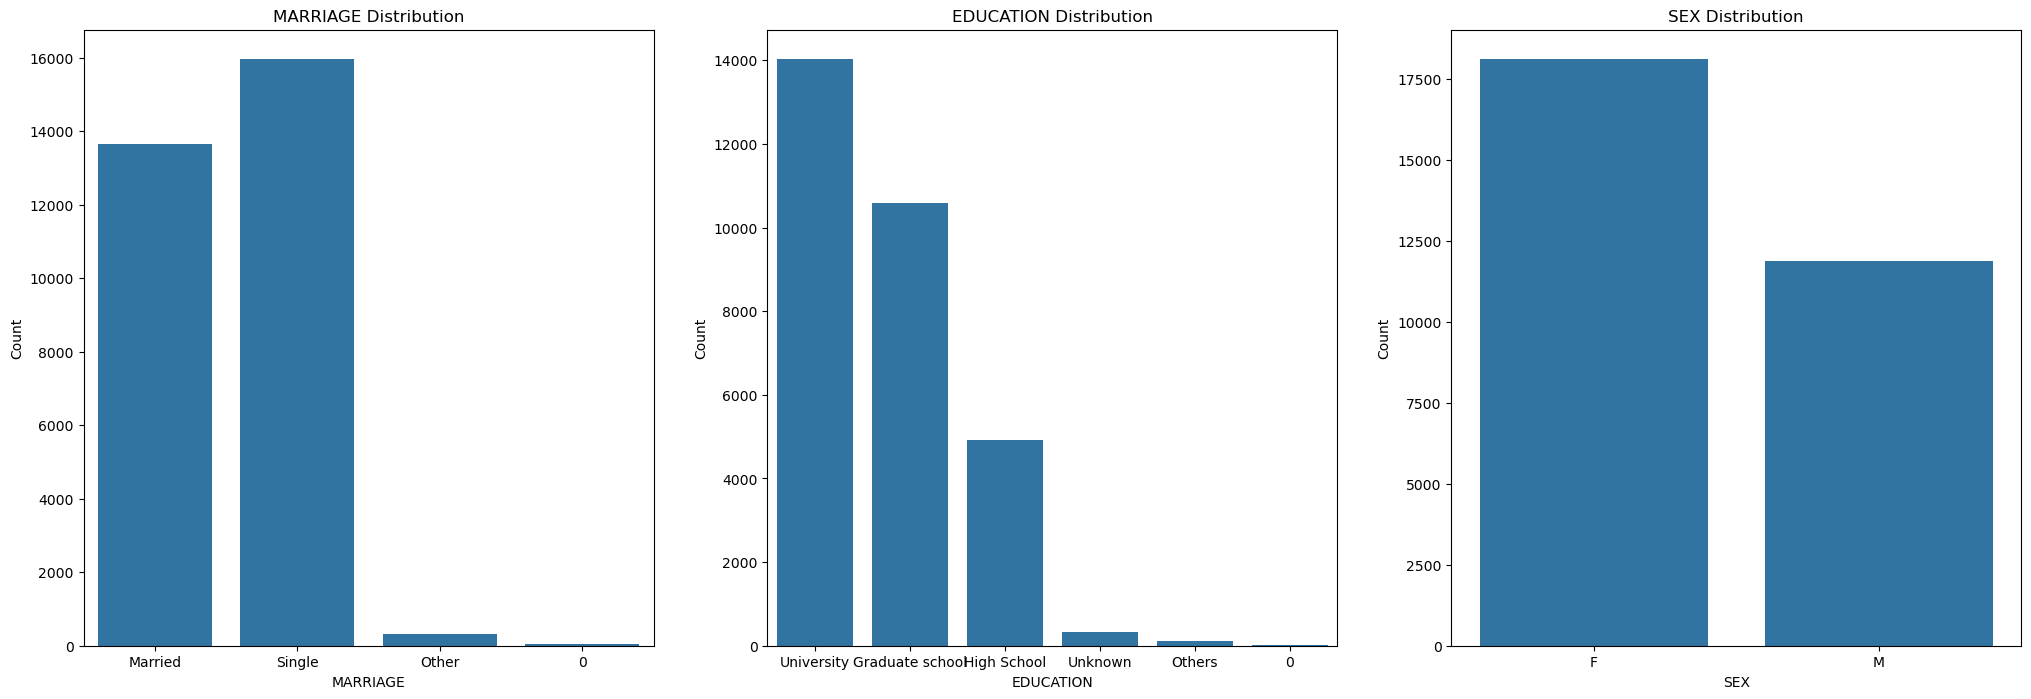

In [19]:
col=['MARRIAGE','EDUCATION','SEX']
fig,ax=plt.subplots(1,3, figsize=(25, 8))

for axi,i in zip(ax.flatten(),col):
  sns.countplot(data=df, x=i, ax=axi)
  axi.set_title(f"{i} Distribution")
  axi.set_xlabel(i)
  axi.set_ylabel("Count")

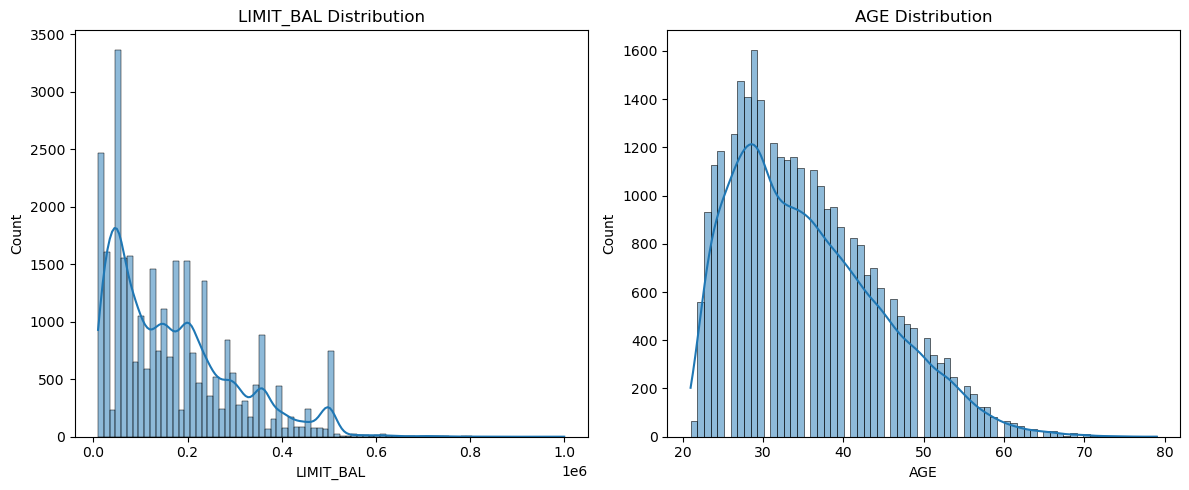

In [20]:
features=["LIMIT_BAL", "AGE"]

fig, axes = plt.subplots(1,2,figsize=(12, 5))

for ax,i in zip(axes, features):
    sns.histplot(data=df, x=i, kde=True, ax=ax)
    ax.set_title(f"{i} Distribution")
    ax.set_xlabel(i)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

Repayment status

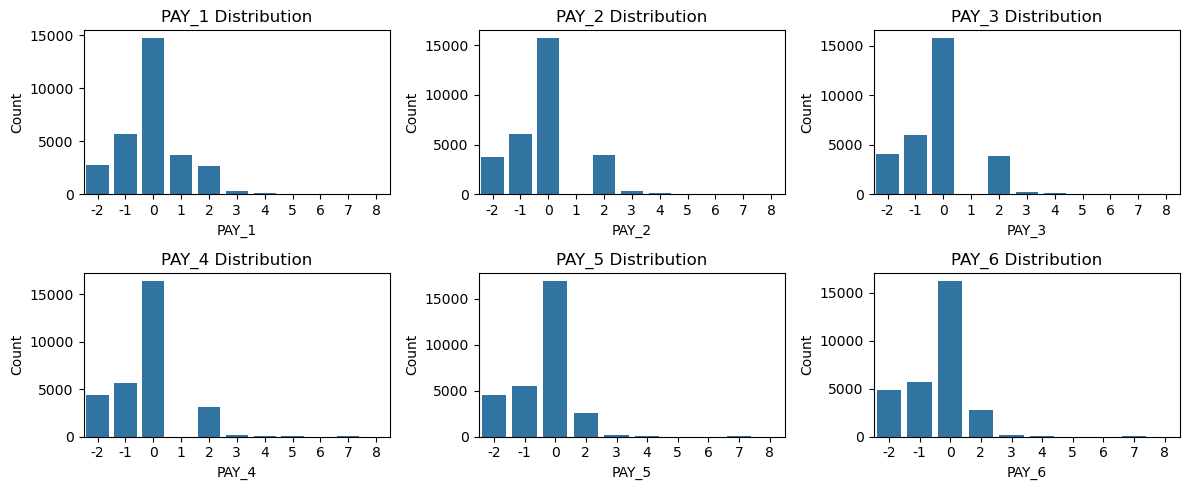

In [21]:
pay_features=["PAY_1", "PAY_2", "PAY_3","PAY_4", "PAY_5", "PAY_6"]

fig,ax=plt.subplots(2,3, figsize=(12, 5))

for axi,i in zip(ax.flatten(),pay_features):
  sns.countplot(data=df, x=i, ax=axi)
  axi.set_title(f"{i} Distribution")
  axi.set_xlabel(i)
  axi.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [26]:
# Melt the dataset to transform the categorical columns to rows-- melt() converts those columns into two columns
pay_df = df.melt(value_vars=['PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6'], var_name='Category', value_name='Value')

# Group the data by category and value and count the number of occurrences
group_df = pay_df.groupby(['Category', 'Value']).size().reset_index(name='Count')

#Create a dictionary to rename int values to cat values
#(-2=no consumption, -1=pay duly, 0=the use of revolving credit, 1=payment delay for one month, 2=payment delay for two months,... 8=payment delay for eight months, 9=payment delay for nine months and above)
value_map = {-2:'no consumption', -1:'paid', 0:'revolving credit', 1:'1 month delay', 2:'2 month delay', 3:'3 month delay',
              4:'4 month delay', 5:'5 month delay', 6:'6 month delay', 7:'7 month delay', 8:'8 month delay', 9:'9 month and more delay'}

In [27]:
#Replace the codes with meaningful text (Fixed typo: changed group_df to grouped_df)
grouped_df['Value'] = group_df['Value'].replace(value_map)

In [28]:
print(pay_df.head(3))
print("\n", group_df.head(5))
print("\n",value_map)
print("\n",grouped_df.head())

  Category  Value
0    PAY_1      2
1    PAY_1     -1
2    PAY_1      0

   Category  Value  Count
0    PAY_1     -2   2759
1    PAY_1     -1   5686
2    PAY_1      0  14737
3    PAY_1      1   3688
4    PAY_1      2   2667

 {-2: 'no consumption', -1: 'paid', 0: 'revolving credit', 1: '1 month delay', 2: '2 month delay', 3: '3 month delay', 4: '4 month delay', 5: '5 month delay', 6: '6 month delay', 7: '7 month delay', 8: '8 month delay', 9: '9 month and more delay'}

   Category             Value  Count
0    PAY_1    no consumption   2759
1    PAY_1              paid   5686
2    PAY_1  revolving credit  14737
3    PAY_1     1 month delay   3688
4    PAY_1     2 month delay   2667


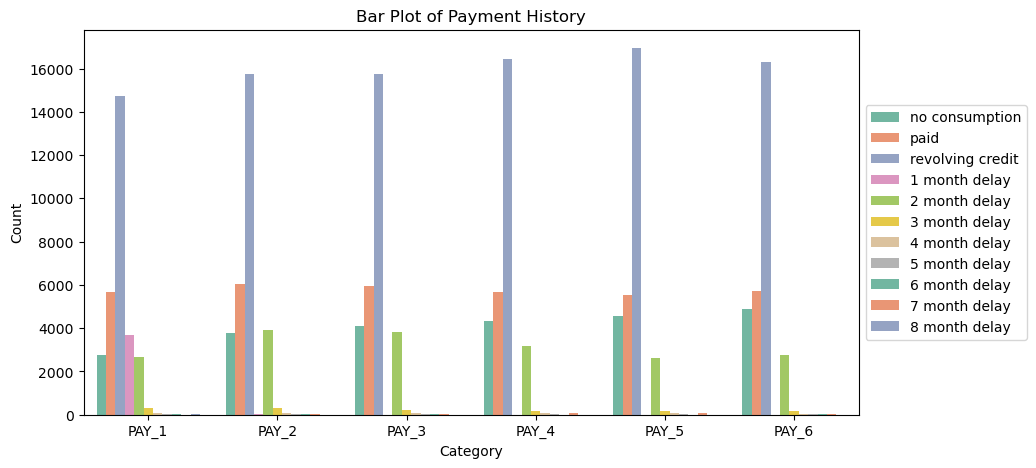

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
bar = sns.barplot(data=grouped_df, x='Category', y='Count',palette='Set2',hue='Value')
bar.set_title('Bar Plot of Payment History')
lgd = plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

plt.show()

In every month's payment history, most customers are from rotating credit followed by paid.
Customers with payment delay in all the payment history have the most number in 2-month payment delay means a 2-month payment delay is a critical sign of the default of the payment.
Some peoplr even not used the card

In [30]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,F,University,Married,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,F,University,Single,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,F,University,Single,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,F,University,Married,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,M,University,Married,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


# Outliers

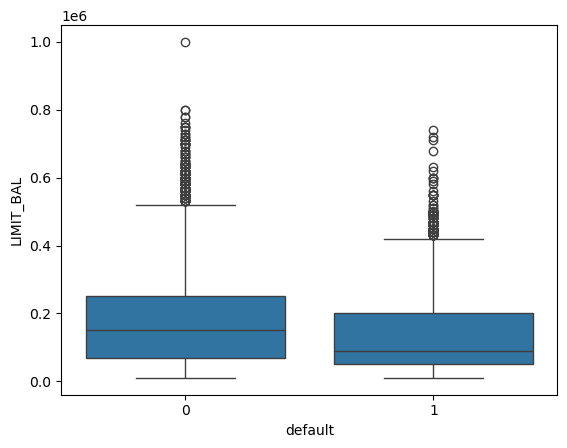

In [31]:
sns.boxplot(data=df, x="default", y="LIMIT_BAL")
plt.show()

**Correlation analysis**

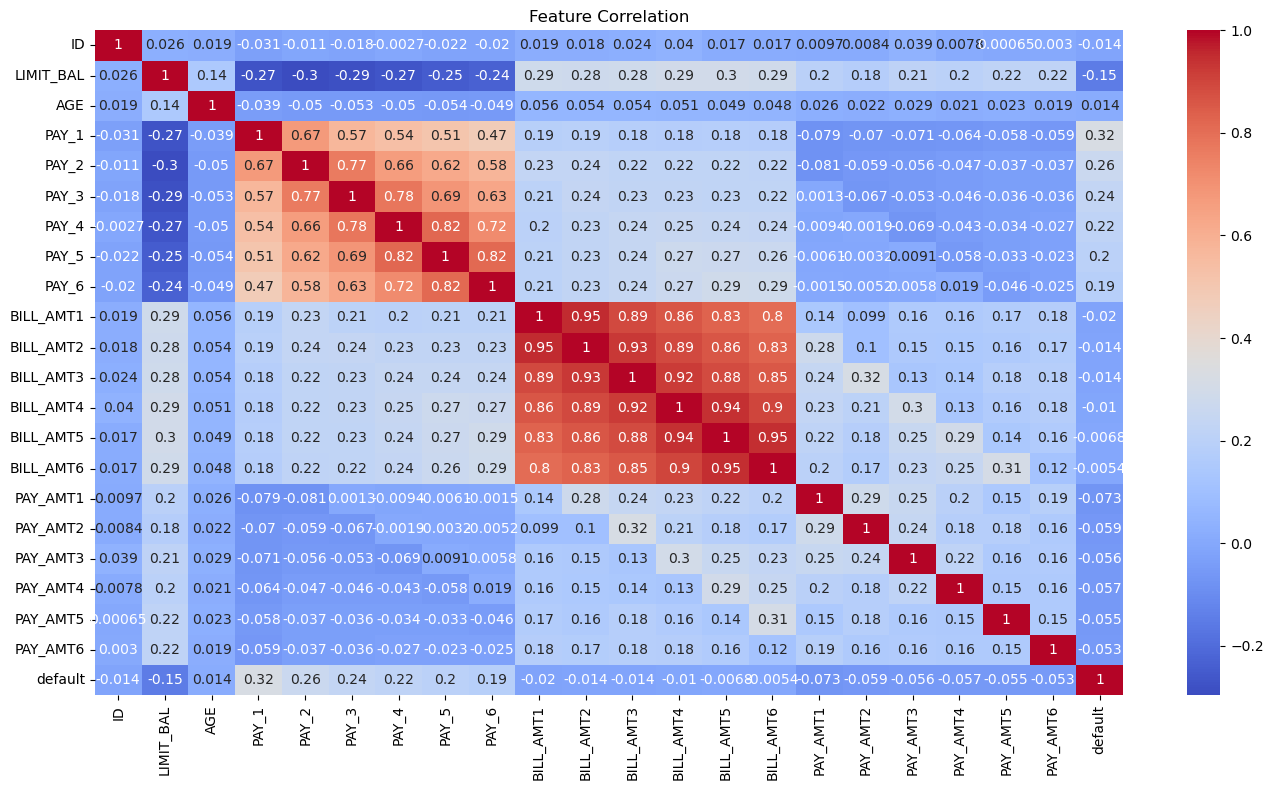

In [32]:
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(14,8))
sns.heatmap(corr, annot=True,cmap='coolwarm')
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

* BILL_AMT1–BILL_AMT6 have very strong positive correlations around 0.83–0.95 so,
customers with high bills in one month tend to have high bills in other months
* PAY_0–PAY_6 also have strong positive correlations up to about 0.82 while customer's repayment status tends to be related across different months
* LIMIT_BAL has only weak/moderate relationships with most other variables 0.14–0.30
* AGE has very weak correlations with most variables close to 0

**Feature Engineering**

Average Bill, Average Payment, Credit Utilization

In [33]:
df["avg_bill"] = df[["BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6"]].mean(axis=1).round(3)


df["avg_payment"] = df[["PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6"]].mean(axis=1).round(3)

df["credit_utilization"] = (df["avg_bill"] /df["LIMIT_BAL"])

In [34]:
df.head(3)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,avg_bill,avg_payment,credit_utilization
0,1,20000,F,University,Married,24,2,2,-1,-1,...,0,689,0,0,0,0,1,1284.000,114.833,0.064200
1,2,120000,F,University,Single,26,-1,2,0,0,...,0,1000,1000,1000,0,2000,1,2846.167,833.333,0.023718
2,3,90000,F,University,Single,34,0,0,0,0,...,1518,1500,1000,1000,1000,5000,0,16942.167,1836.333,0.188246


Delay Count

In [35]:
pay_cols = ["PAY_1","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6"]

df["delay_count"] = (df[pay_cols] > 0).sum(axis=1)


In [36]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,avg_bill,avg_payment,credit_utilization,delay_count
0,1,20000,F,University,Married,24,2,2,-1,-1,...,689,0,0,0,0,1,1284.000,114.833,0.064200,2
1,2,120000,F,University,Single,26,-1,2,0,0,...,1000,1000,1000,0,2000,1,2846.167,833.333,0.023718,2
2,3,90000,F,University,Single,34,0,0,0,0,...,1500,1000,1000,1000,5000,0,16942.167,1836.333,0.188246,0
3,4,50000,F,University,Married,37,0,0,0,0,...,2019,1200,1100,1069,1000,0,38555.667,1398.000,0.771113,0
4,5,50000,M,University,Married,57,-1,0,-1,0,...,36681,10000,9000,689,679,0,18223.167,9841.500,0.364463,0


In [38]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 3.8 MB/s eta 0:00:13
    --------------------------------------- 1.0/48.9 MB 2.4 MB/s eta 0:00:20
   - -------------------------------------- 1.8/48.9 MB 2.8 MB/s eta 0:00:17
   -- ------------------------------------- 2.6/48.9 MB 2.9 MB/s eta 0:00:16
   -- ------------------------------------- 3.1/48.9 MB 3.0 MB/s eta 0:00:16
   --- ------------------------------------ 3.9/48.9 MB 3.1 MB/s eta 0:00:15
   --- ------------------------------------ 4.7/48.9 MB 3.1 MB/s eta 0:00:15
   ---- ----------------------------------- 5.5/48.9 MB 3.2 MB/s eta 0:00:14
   ----- ---------------------------------- 6.8/48.9 MB 3.6 MB/s eta 0:00:12
   ------ --------------------------------- 8.4/48.9 MB 3.9 MB/s eta 0:00:11
   ------- -------------------------------- 9.7/48.9 MB 4.1 MB/s eta 0:00:10
   -------- ------------------------------- 11.0/48.9 MB 4.3 MB/s eta 0:00:09
   --

In [39]:
from sklearn.model_selection import (train_test_split,StratifiedKFold,
                                     RandomizedSearchCV,cross_val_score)

from sklearn.preprocessing import (StandardScaler, OneHotEncoder)

from sklearn.metrics import (accuracy_score,precision_score,recall_score,
    f1_score,roc_auc_score)

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate

from imblearn.over_sampling import SMOTE

In [40]:
X = df.drop(["default","ID"],axis=1)

y = df["default"]

In [41]:
print(X.shape)
y.shape

(30000, 27)


(30000,)

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(24000, 27)
(6000, 27)
(24000,)
(6000,)


**Identify Columns**
- Categorical
- Numerical

In [43]:
categorical_cols = ["SEX","EDUCATION","MARRIAGE"]

In [44]:
numerical_cols = [col for col in X.columns if col not in categorical_cols]

In [45]:
from sklearn.compose import ColumnTransformer

preprocessor_linear = ColumnTransformer(transformers=[("num",StandardScaler(),numerical_cols),
                                                      ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_cols)])
preprocessor_linear


ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['LIMIT_BAL', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3',
                                  'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1',
                                  'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
                                  'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
                                  'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4',
                                  'PAY_AMT5', 'PAY_AMT6', 'avg_bill',
                                  'avg_payment', 'credit_utilization',
                                  'delay_count']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['SEX', 'EDUCATION', 'MARRIAGE'])])

In [46]:
preprocessor_tree = ColumnTransformer(transformers=[("cat",OneHotEncoder(handle_unknown="ignore"),categorical_cols)],
                                      remainder="passthrough")
preprocessor_tree

ColumnTransformer(remainder='passthrough',
                  transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['SEX', 'EDUCATION', 'MARRIAGE'])])

# Model Building
- Logistic Regression
- KNN
- Decision Tree
- Random Forest
- XG Boost

In [47]:
from sklearn.pipeline import Pipeline
lr_pipeline= Pipeline([("prep",preprocessor_linear),
              ("model",LogisticRegression(class_weight="balanced",max_iter=1000))])
lr_pipeline

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['LIMIT_BAL', 'AGE', 'PAY_1',
                                                   'PAY_2', 'PAY_3', 'PAY_4',
                                                   'PAY_5', 'PAY_6',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AMT3', 'PAY_AMT4',
                                                   'PAY_AMT5', 'PAY_AMT6',
                                                   'avg_bill', 'avg_payment',
                                                   'credit_utilization',
                                                   'delay_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [48]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

knn_pipeline= ImbPipeline([("prep", preprocessor_linear),
                           ("smote", SMOTE(random_state=42)),
                          ("model", KNeighborsClassifier(n_neighbors=5))])
#knn_pipeline = Pipeline([("preprocessor",preprocessor_linear),
                         #("model",KNeighborsClassifier())])
knn_pipeline

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['LIMIT_BAL', 'AGE', 'PAY_1',
                                                   'PAY_2', 'PAY_3', 'PAY_4',
                                                   'PAY_5', 'PAY_6',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AMT3', 'PAY_AMT4',
                                                   'PAY_AMT5', 'PAY_AMT6',
                                                   'avg_bill', 'avg_payment',
                                                   'credit_utilization',
                                                   'delay_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE'])])),
                ('smote', SMOTE(random_state=42)),
                ('model', KNeighborsClassifier())])

In [49]:
dt_pipeline = Pipeline([("prep",preprocessor_tree),
                        ("model",DecisionTreeClassifier(class_weight="balanced",random_state=42))])
dt_pipeline

Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE'])])),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

In [50]:
rf = Pipeline([("prep",preprocessor_tree),
                        ("model",RandomForestClassifier(n_estimators=300,class_weight="balanced",
                                                        random_state=42,n_jobs=-1))])

In [51]:
xgb = ImbPipeline([("preprocessor", preprocessor_tree),
                   ("smote", SMOTE(random_state=42)),
                   ("model", XGBClassifier(n_estimators=300,learning_rate=0.05,max_depth=5,
                                           random_state=42,eval_metric="logloss",n_jobs=-1))])

In [52]:
models = {
    "Logistic Regression": lr_pipeline,
    "KNN + SMOTE": knn_pipeline,
    "Decision Tree": dt_pipeline,
    "Random Forest": rf,
    "XGBoost + SMOTE": xgb
}

Stratified Cross Validation
- becoz class is imbalanced

In [53]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [54]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="prior")

baseline_score = cross_val_score(baseline,
                                 X_train,y_train,
                                 cv=cv,scoring="roc_auc").mean()

print("Baseline ROC-AUC:", baseline_score)

Baseline ROC-AUC: 0.5


In [55]:
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

In [56]:
results = []

for name, model in models.items():

    scores = cross_validate(model,X_train,y_train,
                            cv=cv,scoring=scoring,n_jobs=-1)

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean()
    })

In [57]:
results_df = pd.DataFrame(results)

results_df

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Logistic Regression,0.758007,0.512716,0.478175,0.589945,0.528159
1,KNN + SMOTE,0.691455,0.368740,0.352538,0.621776,0.449922
2,Decision Tree,0.616229,0.294327,0.402206,0.402148,0.402045
3,Random Forest,0.771212,0.538921,0.659777,0.355244,0.461778
4,XGBoost + SMOTE,0.782614,0.559158,0.651951,0.390471,0.488380


- All ML models performed better than baseline.
- XGBoost had the best ROC-AUC (0.783) and PR-AUC (0.559).
- Random Forest had the highest precision (0.660).
- Logistic Regression had the highest recall (0.590) and F1 (0.528).
- Promising models: XGBoost, Random Forest, Logistic Regression.
- KNN and Decision Tree were dropped due to weaker overall performance.

# Hyperparameter Tuning
- using RandomizedSearchCV becoz i had multiple hyperparameters with relatively large search spaces and gridsearchCV evaluates every possible combination, which can become computationally expensive. RandomizedSearchCV samples a fixed number of combinations, giving a good balance between search quality and computation time
- That's why i selected RandomizedSearchCV because I was tuning multiple models with several hyperparameters. It allowed me to explore a broader search space with fewer CV evaluations while keeping the test set completely untouched

logistic

In [58]:
from scipy.stats import loguniform

lr_params = {
    "model__C": loguniform(1e-4, 1e2)  #search from 0.0001 to 100 these are search boundaries
}

lr = RandomizedSearchCV(lr_pipeline, param_distributions=lr_params,n_iter=30,
                               cv=cv,scoring="roc_auc",random_state=42,n_jobs=-1)

lr.fit(X_train, y_train)

print("Best Parameters:", lr.best_params_)
print("Best CV ROC-AUC:", lr.best_score_)

Best Parameters: {'model__C': np.float64(15.741890047456648)}
Best CV ROC-AUC: 0.758088155169063


- Before tuning CV ROC-AUC = 0.758007
- After tuning CV ROC-AUC = 0.758087
- By comparing we cam  say improvement is extremely small That means the original C setting was already close to optimal.



```
# WHY C is 15.74
```
- The value 15.74 was selected because it produced the highest mean ROC-AUC across the cross-validation folds.


For Logistic Regression, I tuned the C hyperparameter because it controls the inverse of regularization strength. A smaller C applies stronger regularization, while a larger C applies weaker regularization. Since the useful value can vary across several orders of magnitude, I used a logarithmic search space from 0.0001 to 1000 rather than testing values linearly. RandomizedSearchCV sampled candidate values from this range and evaluated them using 5-fold cross-validation with ROC-AUC. The best value found for my dataset was C = 15.74, with a CV ROC-AUC of 0.7581

- 15.74 isn't a universally correct value. It was the value that gave the highest mean cross-validation ROC-AUC among the candidates sampled during tuning

Random forest

In [ ]:
#rf_params = {
#    "model__n_estimators": [100, 200, 300, 500],
#    "model__max_depth": [5, 10, 15, 20, None],
#    "model__min_samples_split": [2, 5, 10],
#    "model__min_samples_leaf": [1, 2, 4, 8],
#    "model__max_features": ["sqrt", "log2", None]
#}

#rf_random = RandomizedSearchCV(rf,param_distributions=rf_params,n_iter=10,cv=cv,
#                              scoring="roc_auc", random_state=42,n_jobs=-1)

#rf_random.fit(X_train, y_train)

#print("Best Parameters:", rf_random.best_params_)
#print("Best CV ROC-AUC:", rf_random.best_score_)

Random Forest hyperparameter tuning was computationally expensive, so the model was retained using its baseline CV performance, while XGBoost was prioritized for further tuning due to its stronger initial CV performance. EVEN with 10 iterations


In [59]:
xgb_params = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

xgb_random = RandomizedSearchCV(xgb,param_distributions=xgb_params,n_iter=10,cv=cv,scoring="roc_auc",
                                random_state=42,n_jobs=-1)

xgb_random.fit(X_train, y_train)

print("Best Parameters:", xgb_random.best_params_)
print("Best CV ROC-AUC:", xgb_random.best_score_)

C:\Users\gyaneshwar\anaconda4\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\gyaneshwar\anaconda4\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\gyaneshwar\anaconda4\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\gyaneshwar\anaconda4\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~

Best Parameters: {'model__subsample': 0.8, 'model__n_estimators': 300, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}
Best CV ROC-AUC: 0.7864121378731784


Hyperparameter tuning improved XGBoost ROC-AUC from 0.783 to 0.786 and the tuned XGBoost model achieved the best CV ROC-AUC and was selected as the leading candidate. Random Forest tuning was computationally expensive, so its original CV performance (0.771) was retained for comparison.

 I choose the final model is xg why becoz xgboost has
- Highest CV ROC-AUC
- Improved from 0.783 → 0.786 after tuning
- Best overall discrimination among the models you've evaluated

In [60]:
best_model = xgb_random.best_estimator_

# lets train final model and predict it to give accurate model

In [61]:
best_model.fit(X_train, y_train)

C:\Users\gyaneshwar\anaconda4\Lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE'])])),
                ('smote', SMOTE(random_state=42)),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.7, device=None,
                               ear...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.03,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [62]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1] # it prints both but we need only defalut so we care about default and our  problem is defalut prediction lets take only default classes in below 0 inderx is non defalut and 1 is default class

Why y_prob? we can calculate ROC-AUC using y_pred, but it evaluates only hard 0/1 decisions and loses ranking information, using y_prob is the correct approach for evaluating the full ROC-AUC and PR-AUC

In [63]:
print(y_pred)
print(y_prob)
y_test_pred=y_pred
y_test_prob=y_prob

[0 0 0 ... 0 0 0]
[0.14932248 0.14763293 0.21782582 ... 0.04913956 0.17686756 0.06796035]


- predict() → Classification decision
- predict_proba() → Probability scores → ROC-AUC and PR-AUC

In [64]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.65      0.38      0.48      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.69      6000
weighted avg       0.80      0.82      0.80      6000



In [65]:
from sklearn.metrics import average_precision_score
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

PR-AUC: 0.5582966535244609
ROC-AUC: 0.7772359806878522


In [66]:
#training pred
y_train_pred = best_model.predict(X_train)
y_train_prob = best_model.predict_proba(X_train)[:, 1]


In [67]:
comparison = pd.DataFrame({
    "Metric": ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"],
    "Train": [
        roc_auc_score(y_train, y_train_prob),
        average_precision_score(y_train, y_train_prob),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred)
    ],
    "Test": [
        roc_auc_score(y_test, y_test_prob),
        average_precision_score(y_test, y_test_prob),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred)
    ]
})



comparison

,Metric,Train,Test
0,ROC-AUC,0.830392,0.777236
1,PR-AUC,0.625731,0.558297
2,Precision,0.702033,0.647134
3,Recall,0.416274,0.382818
4,F1,0.522644,0.481061


Train and test performance are reasonably consistent, with relatively small metric gaps and also this indicates that the tuned XGBoost model generalizes reasonably well to unseen data, with no strong evidence of overfitting

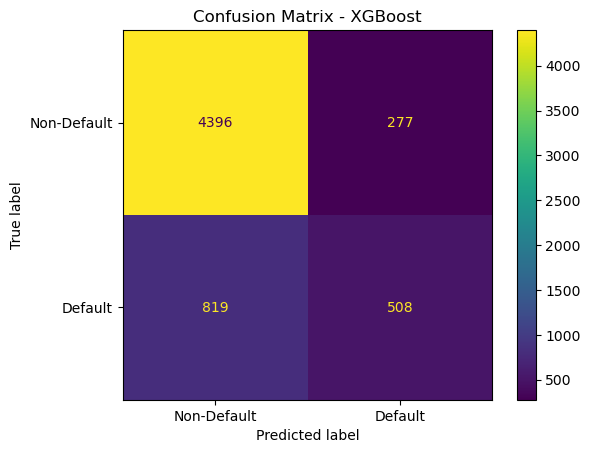

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Non-Default", "Default"])

disp.plot()
plt.title("Confusion Matrix - XGBoost")
plt.show()

- The model correctly identified 4,405 non-default customers

- The model incorrectly flagged 268 non-default customers as defaulters

- The model failed to identify 825 actual defaulters, which represents the key business risk because risky customers may be incorrectly approved

- The model correctly identified 502 actual defaulters missed

The model is strong at identifying non-defaulters, but it misses a considerable number of actual defaulters therefore false negatives are the primary concern, and threshold optimization should be considered if detecting more defaulters is the business priority

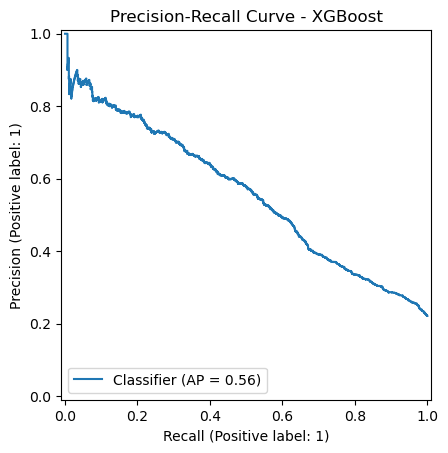

In [69]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Precision-Recall Curve - XGBoost")
plt.show()

PR-AUC is particularly useful because the default class is imbalanced so the model achieves an average precision of approximately 0.56 and increasing recall comes at the cost of lower precision

#threshold analysis

In [70]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test,y_threshold).ravel()

    threshold_results.append({"Threshold": threshold,
                              "TN": tn,
                               "FP": fp,
                               "FN": fn,
                               "TP": tp,
                               "Precision": precision_score(y_test, y_threshold),
                               "Recall": recall_score(y_test, y_threshold),
                               "F1": f1_score(y_test, y_threshold)})

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.2,3172,1501,383,944,0.386094,0.711379,0.500530
1,0.3,3949,724,566,761,0.512458,0.573474,0.541252
2,0.4,4219,454,681,646,0.587273,0.486812,0.532344
3,0.5,4396,277,819,508,0.647134,0.382818,0.481061
4,0.6,4483,190,897,430,0.693548,0.324039,0.441705
5,0.7,4568,105,1027,300,0.740741,0.226074,0.346420


#Feature importance

In [71]:
import pandas as pd

model = best_model.named_steps["model"]

feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame({"Feature": feature_names,
               "Importance": model.feature_importances_}).sort_values(by="Importance",ascending=False)



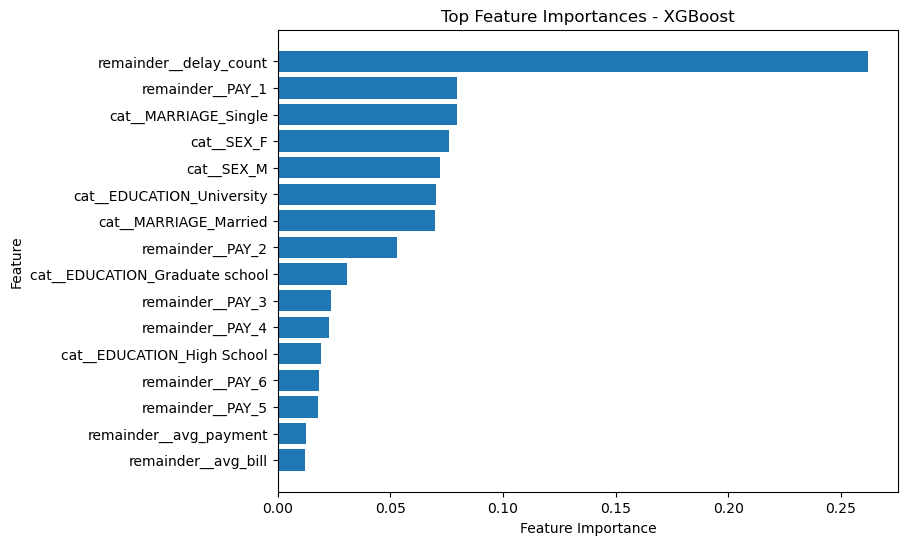

In [72]:
import matplotlib.pyplot as plt

top_features = importance_df.head(16).sort_values("Importance")

plt.figure(figsize=(8, 6))
plt.barh(top_features["Feature"],top_features["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top Feature Importances - XGBoost")
plt.show()

Payment-delay behavior was the most influential predictor in the XGBoost model  followed by selected demographic and repayment-status features and this suggests that historical repayment behavior provides strong predictive signal for credit-default risk

## Business Insights

- XGBoost provided the strongest overall predictive performance among the evaluated models
- Historical payment-delay behavior was the most influential feature in the model, indicating that repayment behavior provides strong predictive signal for credit-default risk
- At the default threshold of 0.50 the model achieved 65.2% precision but only 37.8% recall for the default class
- The confusion matrix showed 825 false negatives, highlighting the risk of missing actual defaulters
- Threshold analysis showed that reducing the threshold to 0.30 increased default recall to 57.7% and reduced false negatives to 561 although false positives increased
- Therefore the optimal threshold depends on the business cost of false positives VS false negatives

## Final Model Conclusion

The evaluated machine learning models were compared using stratified 5-fold cross-validation across ROC-AUC, PR-AUC, precision, recall, and F1-score XGBoost achieved the strongest overall cross-validation performance and was selected for final evaluation

The tuned XGBoost model achieved a cross-validation ROC-AUC of 0.786 and a test ROC-AUC of 0.779 showing reasonably consistent performance on unseen data the test PR-AUC was 0.561

At the default threshold of 0.50, the model achieved 65.2% precision and 37.8% recall for the default class threshold analysis showed that reducing the threshold to 0.30 increased default recall to 57.7% and reduced false negatives from 825 to 561 although false positives increased

Feature-importance analysis showed that historical payment-delay behavior was the most influential predictive feature.

Overall, the model demonstrates useful predictive capability for credit-default risk. In a real-world deployment, the classification threshold should be selected based on the relative business costs of false positives and false negatives.

In [73]:
import joblib

joblib.dump(best_model, "credit_default_xgboost.pkl")

['credit_default_xgboost.pkl']

In [74]:
model = joblib.load('credit_default_xgboost.pkl')

In [75]:
print(X.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'avg_bill', 'avg_payment', 'credit_utilization', 'delay_count']
